<a href="https://colab.research.google.com/github/maharshipatel28/CFD_23BME078/blob/main/Turbulent_Pipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

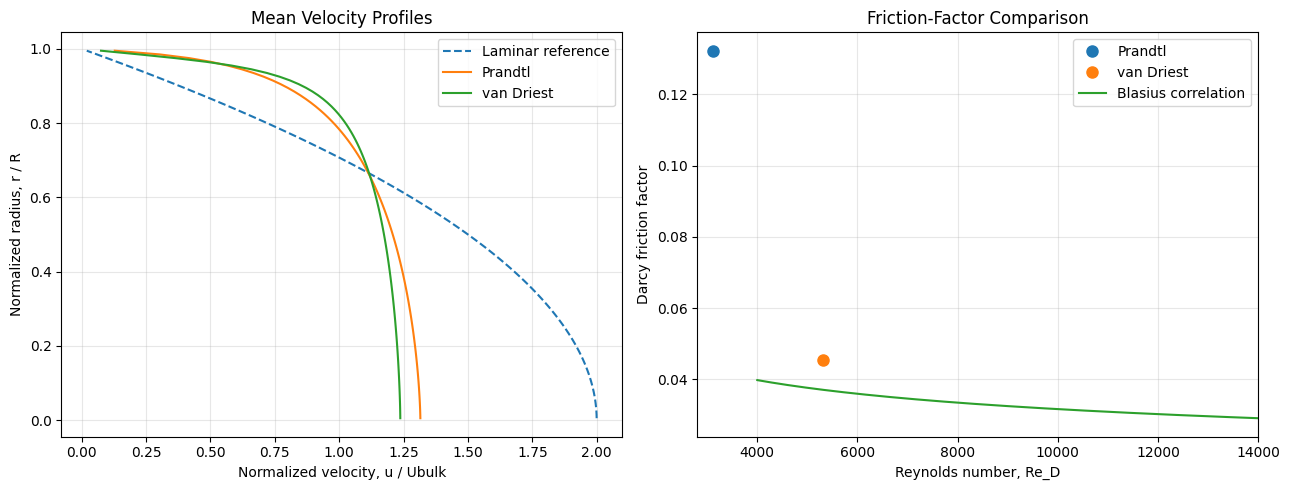

PIPE FLOW SIMULATION RESULTS
Pipe radius             : 0.0200 m
Kinematic viscosity     : 1.500e-05 m^2/s
Density                 : 1.200 kg/m^3
Friction velocity       : 0.1500 m/s
Number of cells         : 100
Friction Reynolds number: 200.00
------------------------------------------------------------
Laminar bulk velocity   : 7.500750 m/s
Laminar FVM max error   : 3.750000e-04 m/s

Model: Prandtl
Bulk velocity           : 1.166517 m/s
Reynolds number         : 3110.71
Darcy friction factor   : 0.132279
Blasius comparison      : 0.042366
Iterations              : 43
Fixed-point residual    : 3.028676e-09

Model: van Driest
Bulk velocity           : 1.992645 m/s
Reynolds number         : 5313.72
Darcy friction factor   : 0.045333
Blasius comparison      : 0.037058
Iterations              : 50
Fixed-point residual    : 8.221446e-10

Simulation completed.
Graph saved as: experiment_10_pipe_output.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

# ============================================================
# 1. PARAMETERS
# ============================================================

R = 0.020
NU = 1.5e-5
RHO = 1.2
U_TAU = 0.15

KAPPA = 0.41
A_PLUS = 26.0

N = 100
MAX_ITER = 5000
TOL = 1.0e-8
RELAX = 0.25

# ============================================================
# 2. GRID GENERATION
# ============================================================

if R <= 0 or NU <= 0 or U_TAU <= 0:
    raise ValueError("R, NU, and U_TAU must be positive.")

if N < 10:
    raise ValueError("N must be at least 10.")

h = R / N

r = (np.arange(N) + 0.5) * h
rf = np.arange(N + 1) * h

volume = np.pi * (rf[1:]**2 - rf[:-1]**2)
area = 2.0 * np.pi * rf

source = 2.0 * U_TAU**2 / R

# ============================================================
# 3. FINITE VOLUME SOLVER
# ============================================================

def solve_linear(eff):

    eff = np.asarray(eff, dtype=float)

    if eff.shape != (N + 1,):
        raise ValueError("Incorrect effective-viscosity array size.")

    if np.any(eff <= 0) or not np.all(np.isfinite(eff)):
        raise ValueError("Effective viscosity must be positive and finite.")

    conductance = area[1:N] * eff[1:N] / h

    diagonal = np.zeros(N)

    diagonal[:-1] += conductance
    diagonal[1:] += conductance

    # No-slip wall boundary condition
    diagonal[-1] += area[-1] * eff[-1] / (0.5 * h)

    matrix = diags(
        [-conductance, diagonal, -conductance],
        offsets=[-1, 0, 1],
        shape=(N, N),
        format="csr"
    )

    rhs = source * volume

    velocity = spsolve(matrix, rhs)

    if not np.all(np.isfinite(velocity)):
        raise RuntimeError("Linear solver returned invalid values.")

    return velocity


# ============================================================
# 4. TURBULENCE MODELS
# ============================================================

def model(name):

    if name not in ("Prandtl", "van Driest"):
        raise ValueError("Unknown turbulence model.")

    velocity = solve_linear(np.full(N + 1, NU))

    y = R - rf

    mixing_length = KAPPA * y

    if name == "van Driest":

        damping = 1.0 - np.exp(
            -y * U_TAU / (A_PLUS * NU)
        )

        mixing_length = mixing_length * damping

    for iteration in range(1, MAX_ITER + 1):

        slope = np.zeros(N + 1)

        slope[1:N] = (
            velocity[1:] - velocity[:-1]
        ) / h

        slope[-1] = -velocity[-1] / (0.5 * h)

        effective_viscosity = (
            NU + mixing_length**2 * np.abs(slope)
        )

        # Molecular viscosity at the wall
        effective_viscosity[-1] = NU

        new_velocity = solve_linear(effective_viscosity)

        difference = np.max(
            np.abs(new_velocity - velocity)
        )

        # Under-relaxation
        velocity = (
            RELAX * new_velocity
            + (1.0 - RELAX) * velocity
        )

        if difference < TOL:
            velocity = new_velocity
            break

    else:
        raise RuntimeError(
            f"{name} did not converge after {MAX_ITER} iterations."
        )

    # Recalculate the final effective viscosity
    slope = np.zeros(N + 1)

    slope[1:N] = (
        velocity[1:] - velocity[:-1]
    ) / h

    slope[-1] = -velocity[-1] / (0.5 * h)

    effective_viscosity = (
        NU + mixing_length**2 * np.abs(slope)
    )

    effective_viscosity[-1] = NU

    residual = np.max(
        np.abs(solve_linear(effective_viscosity) - velocity)
    )

    bulk_velocity = float(
        np.sum(volume * velocity) / (np.pi * R**2)
    )

    reynolds = 2.0 * R * bulk_velocity / NU

    darcy_friction = 8.0 * (U_TAU / bulk_velocity)**2

    return (
        velocity,
        bulk_velocity,
        reynolds,
        darcy_friction,
        iteration,
        residual
    )


# ============================================================
# 5. LAMINAR REFERENCE
# ============================================================

laminar_velocity = solve_linear(np.full(N + 1, NU))

laminar_bulk = float(
    np.sum(volume * laminar_velocity) / (np.pi * R**2)
)

exact_laminar = (
    source * (R**2 - r**2) / (4.0 * NU)
)

laminar_error = float(
    np.max(np.abs(laminar_velocity - exact_laminar))
)

# ============================================================
# 6. RUN MODELS
# ============================================================

results = {}

for model_name in ("Prandtl", "van Driest"):
    results[model_name] = model(model_name)

# ============================================================
# 7. VELOCITY PROFILE GRAPH
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    laminar_velocity / laminar_bulk,
    r / R,
    "--",
    label="Laminar reference"
)

for name, result in results.items():

    velocity, bulk, reynolds, friction, iterations, residual = result

    axes[0].plot(
        velocity / bulk,
        r / R,
        label=name
    )

axes[0].set_xlabel("Normalized velocity, u / Ubulk")
axes[0].set_ylabel("Normalized radius, r / R")
axes[0].set_title("Mean Velocity Profiles")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ============================================================
# 8. FRICTION FACTOR GRAPH
# ============================================================

for name, result in results.items():

    velocity, bulk, reynolds, friction, iterations, residual = result

    axes[1].plot(
        reynolds,
        friction,
        "o",
        markersize=8,
        label=name
    )

re_grid = np.linspace(4000, 14000, 250)

blasius = 0.3164 * re_grid**(-0.25)

axes[1].plot(
    re_grid,
    blasius,
    label="Blasius correlation"
)

# Include all calculated points in the visible x-axis range
re_values = [
    result[2] for result in results.values()
]

x_min = min(4000.0, min(re_values) * 0.90)

axes[1].set_xlim(x_min, 14000)

axes[1].set_xlabel("Reynolds number, Re_D")
axes[1].set_ylabel("Darcy friction factor")
axes[1].set_title("Friction-Factor Comparison")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# Save and display the figure
filename = "experiment_10_pipe_output.png"

plt.savefig(filename, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

# ============================================================
# 9. PRINT RESULTS
# ============================================================

print("=" * 60)
print("PIPE FLOW SIMULATION RESULTS")
print("=" * 60)

print(f"Pipe radius             : {R:.4f} m")
print(f"Kinematic viscosity     : {NU:.3e} m^2/s")
print(f"Density                 : {RHO:.3f} kg/m^3")
print(f"Friction velocity       : {U_TAU:.4f} m/s")
print(f"Number of cells         : {N}")
print(f"Friction Reynolds number: {U_TAU * R / NU:.2f}")

print("-" * 60)

print(f"Laminar bulk velocity   : {laminar_bulk:.6f} m/s")
print(f"Laminar FVM max error   : {laminar_error:.6e} m/s")

for name, result in results.items():

    velocity, bulk, reynolds, friction, iterations, residual = result

    blasius_value = 0.3164 * reynolds**(-0.25)

    print("\nModel:", name)
    print(f"Bulk velocity           : {bulk:.6f} m/s")
    print(f"Reynolds number         : {reynolds:.2f}")
    print(f"Darcy friction factor   : {friction:.6f}")
    print(f"Blasius comparison      : {blasius_value:.6f}")
    print(f"Iterations              : {iterations}")
    print(f"Fixed-point residual    : {residual:.6e}")

print("\nSimulation completed.")
print("Graph saved as:", filename)
print("=" * 60)